In [2]:
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("data")
con = duckdb.connect()
con.execute("SET memory_limit = '8GB'")

for name in ["articles", "customers", "transactions_train"]:
    con.execute(f"CREATE VIEW {name} AS SELECT * FROM '{(DATA / f'{name}.parquet').as_posix()}'")

print(con.execute("SHOW TABLES").df())

                 name
0            articles
1           customers
2  transactions_train


 weeks_ago week_start   rows  buyers
       104 2018-09-20 255648   65019
       103 2018-09-26 417737  105239
       102 2018-10-03 246456   69330
...
 weeks_ago week_start   rows  buyers
         2 2020-09-02 264657   75822
         1 2020-09-09 255241   72019
         0 2020-09-16 240311   68984


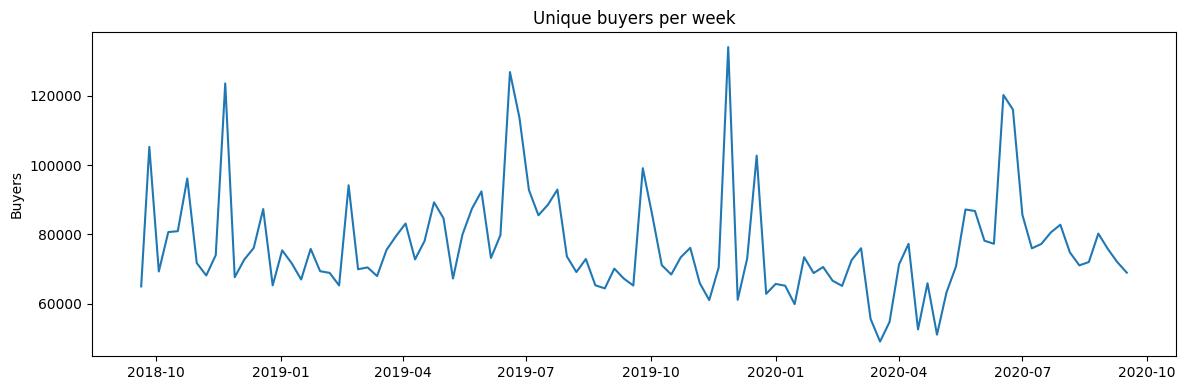

In [3]:
weekly = con.execute("""
    SELECT
        DATE_DIFF('day', t_dat, DATE '2020-09-22') // 7 AS weeks_ago,
        MIN(t_dat) AS week_start,
        COUNT(*) AS rows,
        COUNT(DISTINCT customer_id) AS buyers
    FROM transactions_train
    GROUP BY weeks_ago
    ORDER BY week_start
""").df()

print(weekly.head(3).to_string(index=False))
print("...")
print(weekly.tail(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(weekly["week_start"], weekly["buyers"])
ax.set_title("Unique buyers per week")
ax.set_ylabel("Buyers")
plt.tight_layout()
plt.show()

In [4]:
freq = con.execute("""
    WITH per_customer AS (
        SELECT customer_id, COUNT(DISTINCT t_dat) AS visit_days
        FROM transactions_train
        GROUP BY customer_id
    )
    SELECT
        CASE
            WHEN visit_days = 1 THEN '1 day'
            WHEN visit_days <= 3 THEN '2-3 days'
            WHEN visit_days <= 10 THEN '4-10 days'
            WHEN visit_days <= 30 THEN '11-30 days'
            ELSE '31+ days'
        END AS bucket,
        COUNT(*) AS customers,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
    FROM per_customer
    GROUP BY bucket
    ORDER BY MIN(visit_days)
""").df()
print(freq.to_string(index=False))

print("\nMedian visit days:",
      con.execute("""SELECT MEDIAN(n) FROM (SELECT COUNT(DISTINCT t_dat) n
                     FROM transactions_train GROUP BY customer_id)""").fetchone()[0])

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

    bucket  customers  pct
     1 day     447973 32.9
  2-3 days     296985 21.8
 4-10 days     352338 25.9
11-30 days     224522 16.5
  31+ days      40463  3.0


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


Median visit days: 3.0


In [5]:
print(con.execute("""
    WITH tx AS (
        SELECT customer_id, article_id,
               DATE_DIFF('day', t_dat, DATE '2020-09-22') // 7 AS w
        FROM transactions_train
    ),
    target AS (SELECT DISTINCT customer_id, article_id FROM tx WHERE w = 1),
    hist   AS (SELECT DISTINCT customer_id, article_id FROM tx WHERE w >= 2),
    hist_customers AS (SELECT DISTINCT customer_id FROM tx WHERE w >= 2)
    SELECT
        COUNT(*) AS week1_pairs,
        SUM(CASE WHEN h.customer_id IS NOT NULL THEN 1 ELSE 0 END) AS rebought_pairs,
        ROUND(100.0 * SUM(CASE WHEN h.customer_id IS NOT NULL THEN 1 ELSE 0 END) / COUNT(*), 2) AS rebuy_pct,
        COUNT(DISTINCT t.customer_id) AS week1_buyers,
        COUNT(DISTINCT CASE WHEN hc.customer_id IS NOT NULL THEN t.customer_id END) AS buyers_with_history
    FROM target t
    LEFT JOIN hist h USING (customer_id, article_id)
    LEFT JOIN hist_customers hc ON hc.customer_id = t.customer_id
""").df().to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

 week1_pairs  rebought_pairs  rebuy_pct  week1_buyers  buyers_with_history
      227910          8955.0       3.93         72019                66624


In [6]:
print(con.execute("""
    WITH tx AS (
        SELECT customer_id, article_id,
               DATE_DIFF('day', t_dat, DATE '2020-09-22') // 7 AS w
        FROM transactions_train
    ),
    top12 AS (
        SELECT article_id
        FROM tx WHERE w = 2
        GROUP BY article_id
        ORDER BY COUNT(DISTINCT customer_id) DESC
        LIMIT 12
    ),
    week1 AS (SELECT DISTINCT customer_id, article_id FROM tx WHERE w = 1)
    SELECT
        COUNT(DISTINCT customer_id) AS week1_buyers,
        COUNT(DISTINCT CASE WHEN article_id IN (SELECT article_id FROM top12)
                            THEN customer_id END) AS bought_a_top12_item,
        ROUND(100.0 * COUNT(DISTINCT CASE WHEN article_id IN (SELECT article_id FROM top12)
                            THEN customer_id END) / COUNT(DISTINCT customer_id), 2) AS pct
    FROM week1
""").df().to_string(index=False))

 week1_buyers  bought_a_top12_item  pct
        72019                 4323  6.0


In [7]:
print(con.execute("""
    WITH tx AS (
        SELECT customer_id, article_id, t_dat,
               DATE_DIFF('day', t_dat, DATE '2020-09-22') // 7 AS w
        FROM transactions_train
    ),
    first_sale AS (
        SELECT article_id, MAX(w) AS first_week_ago   -- oldest week = largest w
        FROM tx GROUP BY article_id
    ),
    week1 AS (SELECT DISTINCT customer_id, article_id FROM tx WHERE w = 1)
    SELECT
        CASE
            WHEN f.first_week_ago <= 4  THEN 'a) first sold 0-4 weeks ago'
            WHEN f.first_week_ago <= 12 THEN 'b) 5-12 weeks ago'
            WHEN f.first_week_ago <= 52 THEN 'c) 13-52 weeks ago'
            ELSE 'd) over a year ago'
        END AS item_age,
        COUNT(*) AS week1_pairs,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
    FROM week1 w1
    JOIN first_sale f USING (article_id)
    GROUP BY item_age
    ORDER BY item_age
""").df().to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

                   item_age  week1_pairs  pct
a) first sold 0-4 weeks ago        69057 30.3
          b) 5-12 weeks ago        64362 28.2
         c) 13-52 weeks ago        53554 23.5
         d) over a year ago        40937 18.0


In [8]:
from scipy.stats import chi2_contingency
import numpy as np

table = con.execute("""
    SELECT
        CASE WHEN c.age < 25 THEN '16-24'
             WHEN c.age < 35 THEN '25-34'
             WHEN c.age < 50 THEN '35-49'
             ELSE '50+' END AS age_group,
        a.index_group_name AS product_group,
        COUNT(DISTINCT t.customer_id || t.article_id) AS buys
    FROM transactions_train t
    JOIN customers c USING (customer_id)
    JOIN articles  a USING (article_id)
    WHERE t.t_dat > DATE '2020-09-22' - INTERVAL 84 DAY
      AND t.t_dat <= DATE '2020-09-15'
      AND c.age IS NOT NULL
    GROUP BY ALL
""").df().pivot(index="age_group", columns="product_group", values="buys").fillna(0)

print("Share of each age group's buys (%):")
print((table.div(table.sum(axis=1), axis=0) * 100).round(1).to_string())

chi2, p, dof, _ = chi2_contingency(table)
n = table.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
print(f"\nchi2={chi2:,.0f}  dof={dof}  p={p:.3g}  Cramér's V={cramers_v:.3f}  n={n:,.0f}")

Share of each age group's buys (%):
product_group  Baby/Children  Divided  Ladieswear  Menswear  Sport
age_group                                                         
16-24                    1.0     27.0        60.8       6.1    5.0
25-34                    2.0     20.0        66.7       5.3    6.0
35-49                    3.5     20.5        64.9       6.3    4.8
50+                      1.5     17.8        69.2       7.3    4.2

chi2=34,196  dof=12  p=0  Cramér's V=0.064  n=2,773,394


## EDA: what I learned

Weeks run Wednesday to Tuesday, counting back from the last day (22 Sep 2020). The final week is my test week, so for anything that guides my modelling choices I used the week before it instead.

Sales jump around a lot. There are clear peaks in late November and late June in both years, and a deep dip around April 2020, which I assume was COVID store closures. In a normal week only about 5% of customers buy anything.

A third of customers only ever shopped on one day. The median customer shopped on 3 days in two years, so most people don't give a model much to work with.

People rarely buy the exact same item twice. In my check week, only 3.9% of purchases were repeats. But 92.5% of buyers had bought something before, so "similar to what you bought" might still work even if "the same thing again" doesn't.

Last week's top 12 items were bought by only 6% of the next week's buyers. That tells me every method is going to score low, and I shouldn't expect big numbers.

Fashion moves fast. 30% of purchases were items that had been on sale for about a month or less, and only 18% were items older than a year. So I'll train on recent weeks rather than the full two years. New items also have little sales history, which is where text embeddings should help.

Age does change what people buy, but not by much. Younger customers buy more from Divided (27% vs 18% for 50+), yet Ladieswear dominates every age group. The chi-square test was significant, but with 2.7 million purchases almost anything is. Cramér's V was only 0.064, which is weak. I'll test age-based picks for new customers later, but I'm not expecting a big gain.